# 04c - Figures 2 and 3 of the thesis, and the counting rule of Study 1

Study 1 is estimated in notebook 04. This notebook draws the two figures the
thesis shows for it, in the same visual language as Figure 1 and Figure A1: the six
effects on one common d scale, and the difference in communal words of every occupation ordered
by the share of women in the US labour force.

Nothing is estimated here. Every value of the two figures is read from the tables
that notebook 04 wrote, so the figures cannot drift away from the numbers they
illustrate. The last section prints the counting rule behind those numbers for
Appendix B: which text the hits are counted in, which length stands in the
denominator, and what the cleaning of notebook 02 took out of the biographies.

- **Question:** How do the Study 1 effects look side by side on one scale, how
  does the difference in communal words vary across the 27 occupations, and on which text and
  which length do the four features rest?
- **Expectation:** none; the notebook draws results that already exist.
- **Status:** figures for the thesis, added on 2026-10-31 after notebook 04 was
  final. The underlying estimates are the ones of notebook 04, unchanged.
  The row of F1 was renamed on 2026-11-13, when Study 1 moved to the
  communal balance of Study 2. Revised on 2026-11-15: label of the
  balance, figure numbers. The row of the balance carries no
  hypothesis, because H1a and H1b are fixed on its two parts, and the
  two figures moved down by one when Figure 2 became Figure A1. The
  file names keep the numbers they were written with. Revised on
  2026-11-16: every other row of Figure 2 names the direction fixed in
  advance, and the counting rule of Study 1 was added as a third
  section. Revised on 2026-11-17: axis title and label size. Figure 3
  carries the wording of the thesis, the difference in communal words,
  and its occupation names are set larger. Revised on 2026-11-18:
  Figure 3 carries the pooled difference of Table 1 as a dashed
  reference line, read from the effect sizes of notebook 04.
- **Unit and test:** quantity (Figure 2) and occupation (Figure 3); no test is
  run here. Figure 2 puts the logit effects of F3 and F4 on the d scale with the
  factor of Chinn (2000), as notebook 04 does.
- **Inputs:** `outputs/study1_results/study1_effect_sizes.csv` and
  `outputs/study1_results/study1_beta_by_occupation.csv`, both written by
  notebook 04, and `config/occupation_metadata_27.csv` for the share of women
  per occupation; for the third section also
  `outputs/df_features.parquet` and the dictionary of the main analysis
  through `src/lexicon.py`.
- **Outputs:** `outputs/study1_results/fig3_forest_thesis.png` and
  `outputs/study1_results/fig4_communion_by_occupation_thesis.png`, together
  with the values behind them, printed above each figure.
- **Run:** from a fresh kernel, top to bottom, from the project root or from
  `notebooks/`. The two figures read three tables and need no model, so they
  take seconds; the third section reads the feature table and tokenises a
  sample of biographies, which takes about a minute.
- **Decisions:** the occupations of Study 2 are marked in Figure 3; occupations
  without a BLS counterpart (`dj`, `model`) are kept and shown separately at the
  top, because they are part of Study 1.


In [13]:
# -- Settings and inputs -----------------------------------------------------

# The notebook may be opened from notebooks/, from the project root or from a
# copy in notebooks/archive/. The root is the nearest folder upwards that holds
# both outputs/ and src/, so every path below can be written relative to it.
import os
import pathlib
import sys

ROOT = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / 'outputs').is_dir() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('project root not found: no folder at or above the '
                       'working directory holds both outputs/ and src/')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print(f'working directory: {ROOT.name}')

import pandas as pd
from pathlib import Path

OUT = Path('outputs/study1_results')
occ_meta = pd.read_csv('config/occupation_metadata_27.csv')
print(f'occupation table: {len(occ_meta)} occupations, '
      f'{occ_meta["pct_women_bls_2025"].notna().sum()} of them with a BLS share')


working directory: Thesis_Model
occupation table: 27 occupations, 25 of them with a BLS share


Figure 2 values (d, 95% CI):
  Communion (H1a, expected +)                        +0.1977 [+0.1912, +0.2042]
  Agency (H1b, expected -)                           +0.0528 [+0.0463, +0.0593]
  Communal balance                                   +0.1414 [+0.1349, +0.1479]
  Passive voice (H2a, expected +)                    +0.0336 [+0.0274, +0.0399]
  Achievement words, occurrence (H2b, expected -)    +0.0304 [+0.0183, +0.0425]
  External attribution, occurrence (H2b, expected +) -0.0115 [-0.0299, +0.0070]


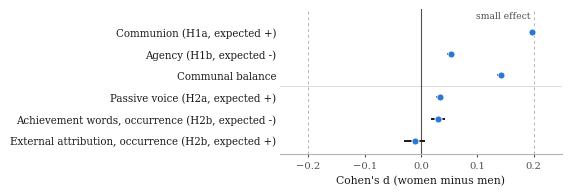

In [14]:
# -- Figure 2: the six effects of Study 1 on one common d scale --------------

# Reads the effect sizes written by notebook 04; nothing is estimated again.
# Expects OUT from the cell above.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'
INK, GREY, LIGHT, BIO, S2_FILL = '#1a1a1a', '#52514e', '#b5b4ae', '#2a78d6', '#f8eddf'
CHINN_FACTOR = np.sqrt(3) / np.pi

# -- Figure 2: six effects on the d scale (section 2) -------------------------
es = pd.read_csv(OUT / 'study1_effect_sizes.csv')
std = es[es['estimand'] == 'beta (standardised)'].copy()
std.index = std['feature'].str.strip()
logit = es[es['estimand'] == 'beta (logit)'].copy()
logit.index = logit['feature'].str.strip()
rows3 = [
    ('Communion (H1a, expected +)', std.loc['F1b communion_rate', ['d', 'ci_lo', 'ci_hi']].values),
    ('Agency (H1b, expected -)', std.loc['F1a agency_rate', ['d', 'ci_lo', 'ci_hi']].values),
    # Every label names the direction the hypothesis fixed in advance,
    # as the column expected_sign of study1_effect_sizes.csv carries it;
    # the sign is written as a plain hyphen, because the notebook is
    # ASCII. No hypothesis is fixed on the balance itself: H1a and H1b
    # are about its two parts, so its row carries neither.
    ('Communal balance', std.loc['F1  communal_balance', ['d', 'ci_lo', 'ci_hi']].values),
    ('Passive voice (H2a, expected +)', std.loc['F2  passive_ratio', ['d', 'ci_lo', 'ci_hi']].values),
    ('Achievement words, occurrence (H2b, expected -)',
     np.r_[logit.loc['F3  achievement', 'd'], logit.loc['F3  achievement', ['ci_lo', 'ci_hi']].values * CHINN_FACTOR]),
    ('External attribution, occurrence (H2b, expected +)',
     np.r_[logit.loc['F4  attribution', 'd'], logit.loc['F4  attribution', ['ci_lo', 'ci_hi']].values * CHINN_FACTOR]),
]
print('Figure 2 values (d, 95% CI):')
for lab, (d, lo, hi) in rows3:
    print(f'  {lab:<50} {d:+.4f} [{lo:+.4f}, {hi:+.4f}]')

fig, ax = plt.subplots(figsize=(5.6, 1.85))
n = len(rows3)
for i, (lab, (d, lo, hi)) in enumerate(rows3):
    y = n - 1 - i
    ax.plot([lo, hi], [y, y], color=INK, lw=1.4, solid_capstyle='butt', zorder=3)
    ax.scatter([d], [y], s=26, color=BIO, edgecolor='white', lw=0.7, zorder=4)
ax.axhline(2.5, color='#dddcd7', lw=0.7)
ax.axvline(0, color=GREY, lw=0.8)
for v in (-0.2, 0.2):
    ax.axvline(v, color=LIGHT, lw=0.7, ls=(0, (3, 3)))
ax.text(0.195, n - 0.45, 'small effect', fontsize=6.6, color=GREY, ha='right', va='bottom')
ax.set_yticks(range(n))
ax.set_yticklabels([r[0] for r in rows3][::-1], fontsize=7.4, color=INK)
ax.set_ylim(-0.6, n + 0.05)
ax.set_xlim(-0.25, 0.25)
ax.set_xlabel("Cohen's d (women minus men)", fontsize=7.8, color=INK)
ax.tick_params(axis='x', labelsize=7.2, colors=GREY, length=2)
ax.tick_params(axis='y', length=0, pad=3)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color(LIGHT)
plt.tight_layout(pad=0.3)
plt.savefig(OUT / 'fig3_forest_thesis.png', dpi=300)
plt.show()


## Figure 3

The difference in communal words of every occupation, ranked by its size, with the interval of
notebook 04. The dashed line marks the pooled difference of Table 1 over all
27 occupations. The colour of a point carries the share of women among the employed
in that occupation (BLS 2025); the two occupations without a BLS counterpart are
drawn hollow, and the occupations of Study 2 are set in bold.


Figure 3: the difference in communal words per occupation, ranked by size
       occupation    beta   ci_lo   ci_hi  pct_women_bls_2025 in_study2
            model -0.8106 -0.9573 -0.6638                 NaN        no
          surgeon -0.1123 -0.2354  0.0108                25.9       yes
          dentist -0.0287 -0.1115  0.0542                38.6       yes
     chiropractor  0.0248 -0.2436  0.2932                31.1        no
        paralegal  0.0319 -0.3874  0.4511                82.4       yes
        architect  0.1076 -0.0099  0.2252                29.8       yes
          painter  0.1310  0.0452  0.2169                59.9        no
               dj  0.1651 -0.1320  0.4623                 NaN        no
             poet  0.1864  0.0856  0.2873                66.8        no
       accountant  0.1968  0.0372  0.3564                59.1       yes
         composer  0.1984  0.0587  0.3382                28.5        no
         comedian  0.2087  0.0087  0.4087                47.8 

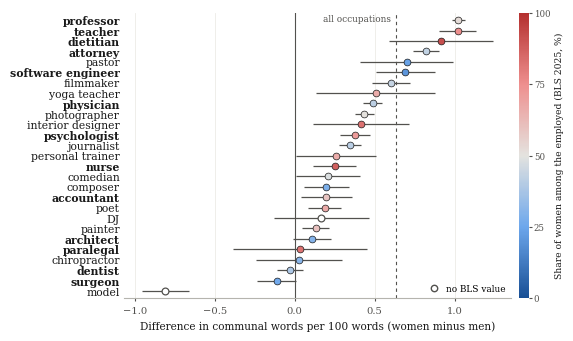

In [15]:
# -- Figure 3: the difference in communal words per occupation, ranked by size, --
# -- coloured by the BLS share of women                                   --
# Reads the per-occupation estimates written by notebook 04 and the BLS shares from the
# occupation table; nothing is estimated again. Expects OUT and occ_meta from the cells above.
# The dashed line marks the pooled difference of Table 1, read from the effect
# sizes notebook 04 wrote, so no value of it is written out here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D

plt.rcParams['font.family'] = 'serif'
INK, GREY, LIGHT = '#1a1a1a', '#52514e', '#b5b4ae'
# diverging scale: blue for occupations dominated by men, red for those dominated by women,
# neutral grey at 50 per cent
SHARE_CMAP = LinearSegmentedColormap.from_list(
    'share_women', ['#184f95', '#6da7ec', '#e4e3df', '#ee8f8e', '#b4302f'])
SHARE_NORM = TwoSlopeNorm(vmin=0, vcenter=50, vmax=100)

occ4 = pd.read_csv(OUT / 'study1_beta_by_occupation.csv')
occ4 = occ4[occ4['quantity'] == 'communion_rate'][['occupation', 'beta', 'ci_lo', 'ci_hi']]
meta4 = occ_meta[['occ', 'pct_women_bls_2025', 'in_study2']].rename(columns={'occ': 'occupation'})
occ4 = occ4.merge(meta4, on='occupation', how='left')
assert len(occ4) == 27 and occ4['in_study2'].notna().all()
occ4 = occ4.sort_values('beta').reset_index(drop=True)   # largest gap at the top

es4 = pd.read_csv(OUT / 'study1_effect_sizes.csv')
pooled4 = es4[(es4['feature'].str.strip() == 'F1b communion_rate')
              & (es4['estimand'] == 'beta (raw)')]['estimate']
assert len(pooled4) == 1, (
    f'study1_effect_sizes.csv carries {len(pooled4)} raw estimates for F1b '
    f'communion_rate; the pooled difference of Table 1 has to be one row.')
POOLED4 = float(pooled4.iloc[0])

print('Figure 3: the difference in communal words per occupation, ranked by size')
print(occ4.round(4).to_string(index=False))
print(f'pooled difference over all occupations (Table 1, OLS with occupation '
      f'effects): {POOLED4:+.4f} communal words per 100 words')
print(f"\npositive: {(occ4['beta'] > 0).sum()} of {len(occ4)}; "
      f"interval above zero: {(occ4['ci_lo'] > 0).sum()}; "
      f"interval below zero: {(occ4['ci_hi'] < 0).sum()}")

fig, ax = plt.subplots(figsize=(5.6, 3.3))
for i, r in occ4.iterrows():
    ax.plot([r['ci_lo'], r['ci_hi']], [i, i], color=GREY, lw=0.9,
            solid_capstyle='butt', zorder=2)
    if pd.notna(r['pct_women_bls_2025']):
        ax.scatter([r['beta']], [i], s=24, zorder=4, edgecolor=INK, lw=0.5,
                   color=SHARE_CMAP(SHARE_NORM(r['pct_women_bls_2025'])))
    else:
        ax.scatter([r['beta']], [i], s=24, zorder=4, color='white', edgecolor=GREY, lw=0.9)

labels = ['DJ' if o == 'dj' else o.replace('_', ' ') for o in occ4['occupation']]
ax.set_yticks(range(len(occ4)))
ax.set_yticklabels(labels, fontsize=7.8, color=INK)
for tick, s2 in zip(ax.get_yticklabels(), occ4['in_study2']):
    if s2 == 'yes':
        tick.set_fontweight('bold')
ax.set_ylim(-0.7, len(occ4) - 0.3)
ax.axvline(0, color=GREY, lw=0.8, zorder=1)
ax.axvline(POOLED4, color=GREY, lw=0.8, ls=(0, (3, 3)), zorder=1)
ax.text(POOLED4 - 0.03, len(occ4) - 0.45, 'all occupations',
        fontsize=6.4, color=GREY, ha='right', va='top')
ax.set_xlabel('Difference in communal words per 100 words (women minus men)',
              fontsize=7.6, color=INK)
ax.tick_params(axis='x', labelsize=7.2, colors=GREY, length=2)
ax.tick_params(axis='y', length=0, pad=3)
ax.grid(axis='x', color='#ecebe7', lw=0.6)
ax.set_axisbelow(True)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color(LIGHT)

# colour key outside the plot, so that it never covers an interval
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=SHARE_CMAP, norm=SHARE_NORM), ax=ax,
                  fraction=0.03, pad=0.02, aspect=28, ticks=[0, 25, 50, 75, 100])
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=6.2, colors=GREY, length=2, pad=1.5)
cb.set_label('Share of women among the employed (BLS 2025, %)', fontsize=6.6, color=INK, labelpad=3)
ax.legend(handles=[Line2D([0], [0], marker='o', color='none', markerfacecolor='white',
                          markeredgecolor=GREY, markersize=4.6, label='no BLS value')],
          loc='lower right', fontsize=6.4, frameon=False, handletextpad=0.3, borderaxespad=0.2)
plt.tight_layout(pad=0.3)
plt.savefig(OUT / 'fig4_communion_by_occupation_thesis.png', dpi=300)
plt.show()


## The counting rule of Study 1

- **Question:** Which text are the dictionary hits counted in, which length
  stands in the denominator of the rates and in ln(Words) of the model, and how
  much do the gender markers and the first names that notebook 02 removed take
  out of the biographies?
- **Expectation:** the words the cleaning removes are the ones notebook 03
  printed, and few dictionary hits lay in them, because what is removed are
  pronouns, titles and first names.
- **Status:** added on 2026-11-16 for Appendix B. The section quotes the two
  columns from the code that produces them and measures the rest; it changes
  nothing in Study 1.
- **Unit and test:** biography; no test. The recount of part 3 runs on a sample
  with a fixed seed and is held against the counts notebook 03 stored, which
  notebook 04b shows the blank tokenizer reproduces exactly.
- **Output:** none; the section prints.

In [16]:
# The counting rule of Study 1, printed for Appendix B: which text the hits are
# counted in, which length stands in the denominator of the rates and in
# ln(Words) of the model, how much the cleaning removes, and how many dictionary
# hits lay in the words it removed. Nothing is estimated again: the counts of
# notebook 03 are read from the feature table, and the recount in part 3 only
# controls this cell against them.
# MKL_THREADING_LAYER as in notebook 04b, cell 1: numpy and spaCy each bring
# their own OpenMP, and SEQUENTIAL keeps the two apart. The cell is written to
# run after the two figures above; from a fresh kernel it also runs on its own.
import os
os.environ.setdefault("MKL_THREADING_LAYER", "SEQUENTIAL")
import time
import numpy as np
import spacy

from src.lexicon import load_lexicons, count_multiword_communion

FEATURES_FILE = Path('outputs/df_features.parquet')
LEX_VERSION = 'A'          # dictionary of the main analysis
SAMPLE_N, SAMPLE_SEED = 20_000, 42
# What notebook 03 printed in cell fe584803, as the reference of the control:
# the words the cleaning removes, overall and by gender.
NB03_WORDS_REMOVED = {'all': 3.79, 'Female': 3.833, 'Male': 3.753}

print('1. Where the numbers of Study 1 come from')
print('   hits of F1, F3 and F4             : text_clean, the cleaned '
      'biography')
print('     notebook 03, cell 3dc9de9f      : '
      "texts_all = df['text_clean'].tolist()")
print('   denominator of every rate         : word_count, the length of '
      'hard_text')
print('     src/preprocessing.py, line 63   : '
      "df['word_count'] = df['hard_text'].str.split().str.len()")
print('   ln(Words) of the model            : np.log(word_count), the same '
      'column')
print('     notebook 04, cell 9f775dfd      : '
      "df['log_wc'] = np.log(df['word_count'])")
print('   so the numerator is counted after the markers and the names were '
      'removed,')
print('   and the denominator is the length of the biography before that.')

df_count = pd.read_parquet(FEATURES_FILE,
                           columns=['hard_text', 'text_clean', 'gender_label',
                                    'word_count', 'agency_count',
                                    'communion_count'])
print(f'\n   read: {FEATURES_FILE}, {len(df_count):,} biographies, '
      f'dictionary {LEX_VERSION}')

# Control: word_count is the length of hard_text and not of text_clean.
words_hard = df_count['hard_text'].str.split().str.len()
words_clean = df_count['text_clean'].str.split().str.len()
n_off_hard = int((words_hard != df_count['word_count']).sum())
n_off_clean = int((words_clean != df_count['word_count']).sum())
print(f'   control word_count against the length of hard_text : {n_off_hard} '
      f'deviations (expected 0)')
print(f'   control word_count against the length of text_clean: '
      f'{n_off_clean:,} deviations (the two have to differ)')
if n_off_hard:
    raise AssertionError(
        f'word_count deviates from the length of hard_text in {n_off_hard} '
        f'biographies, so the denominator is not the raw length.')
if n_off_clean == 0:
    raise AssertionError(
        'word_count equals the length of text_clean everywhere, which the '
        'removal of the markers rules out.')

print('\n2. The length before and after the cleaning, in words')
df_count['words_removed'] = df_count['word_count'] - words_clean
print(f"  {'group':<8} {'n':>8} {'before':>8} {'after':>8} {'removed':>8} "
      f"{'share':>7} {'notebook 03':>12} {'deviation':>11}")
print('  ' + '-' * 77)
for group in ('all', 'Female', 'Male'):
    rows = (df_count if group == 'all'
            else df_count[df_count['gender_label'] == group])
    removed = float(rows['words_removed'].mean())
    reference = NB03_WORDS_REMOVED[group]
    print(f'  {group:<8} {len(rows):>8,} {rows["word_count"].mean():>8.3f} '
          f'{(rows["word_count"] - rows["words_removed"]).mean():>8.3f} '
          f'{removed:>8.3f} '
          f'{float((rows["words_removed"] / rows["word_count"]).mean()):>7.2%} '
          f'{reference:>12.3f} {removed - reference:>+11.4f}')
_gap = (float(df_count[df_count['gender_label'] == 'Male']['words_removed']
              .mean())
        - float(df_count[df_count['gender_label'] == 'Female']['words_removed']
                .mean()))
print(f'  men minus women: {_gap:+.3f} words')

print(f'\n3. The dictionary hits that lay in the removed words, on a sample of '
      f'{SAMPLE_N:,} biographies (seed {SAMPLE_SEED})')
lex_main = load_lexicons(version=LEX_VERSION)
nlp_tok = spacy.blank('en')          # tokenizer only, no tagger and no parser
print(f'  tokenizer pipeline: {nlp_tok.pipe_names or "[] (tokenizer only)"}')


def count_hits(text_list):
    """Agency and communion hits per biography, as src/features.py counts them.

    Only token.lower_ and the raw text for the multi-word communion entries are
    read, so the blank tokenizer is enough; notebook 04b, section 1.1, shows
    that it reproduces the counts of notebook 03 exactly.
    """
    agency, communion = [], []
    for text, doc in zip(text_list, nlp_tok.pipe(text_list, batch_size=1024)):
        agency.append(sum(1 for t in doc if lex_main.match_agency(t.lower_)))
        communion.append(
            sum(1 for t in doc if lex_main.match_communion(t.lower_))
            + count_multiword_communion(text.lower(),
                                        lex_main.multi_word_communion))
    return np.asarray(agency, dtype=np.int64), np.asarray(communion,
                                                          dtype=np.int64)


_rng = np.random.default_rng(SAMPLE_SEED)
_sample = df_count.iloc[np.sort(_rng.choice(len(df_count), SAMPLE_N,
                                            replace=False))]
_t0 = time.time()
ag_clean, co_clean = count_hits(_sample['text_clean'].tolist())
ag_hard, co_hard = count_hits(_sample['hard_text'].tolist())
print(f'  runtime {time.time() - _t0:.1f}s for both texts of the sample')

# Control: on text_clean the recount has to reproduce the stored counts.
_off_ag = int((ag_clean != _sample['agency_count'].to_numpy()).sum())
_off_co = int((co_clean != _sample['communion_count'].to_numpy()).sum())
print(f'  control against the stored counts of notebook 03: agency {_off_ag}, '
      f'communion {_off_co} deviations (expected 0)')
if _off_ag or _off_co:
    raise AssertionError(
        'The recount on text_clean deviates from the counts in '
        'df_features.parquet, so the two are not comparable.')

print(f"\n  {'group':<8} {'n':>7} {'dimension':<10} {'hard_text':>10} "
      f"{'text_clean':>11} {'removed':>8} {'share':>7}")
print('  ' + '-' * 66)
_is_female = (_sample['gender_label'] == 'Female').to_numpy()
for group, mask in (('all', np.ones(len(_sample), bool)),
                    ('Female', _is_female), ('Male', ~_is_female)):
    for dimension, hard, clean in (('agency', ag_hard, ag_clean),
                                   ('communion', co_hard, co_clean)):
        before, after = hard[mask].mean(), clean[mask].mean()
        print(f'  {group:<8} {int(mask.sum()):>7,} {dimension:<10} '
              f'{before:>10.4f} {after:>11.4f} {before - after:>8.4f} '
              f'{(before - after) / before:>7.2%}')
print('  hard_text and text_clean are counted with the same dictionary and the '
      'same tokenizer,')
print('  so the difference is what the removed words carried; it is a mean per '
      'biography.')

1. Where the numbers of Study 1 come from
   hits of F1, F3 and F4             : text_clean, the cleaned biography
     notebook 03, cell 3dc9de9f      : texts_all = df['text_clean'].tolist()
   denominator of every rate         : word_count, the length of hard_text
     src/preprocessing.py, line 63   : df['word_count'] = df['hard_text'].str.split().str.len()
   ln(Words) of the model            : np.log(word_count), the same column
     notebook 04, cell 9f775dfd      : df['log_wc'] = np.log(df['word_count'])
   so the numerator is counted after the markers and the names were removed,
   and the denominator is the length of the biography before that.

   read: outputs\df_features.parquet, 393,977 biographies, dictionary A
   control word_count against the length of hard_text : 0 deviations (expected 0)
   control word_count against the length of text_clean: 380,549 deviations (the two have to differ)

2. The length before and after the cleaning, in words
  group           n   before 